In [1]:
%matplotlib inline

import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual

import skimage as ski
import numpy as np
from scipy import ndimage as ndi
from matplotlib import pyplot as plt
from skimage import morphology
from skimage.color import label2rgb
import skimage.io as io

In [2]:
data_dir = ('sekvence//')

### 1. ZADATAK
## PRVA TACKA

Kako je pozadina svake originalne slike zelene boje, najjednostavniji nacin za resavanje ovog zadatka jeste da se ulazna slika najpre prebaci u HSV kolor sistem, gde sam na taj nacin pomocu H i S kanala uspeo da realizujem dobru masku. Prvenstveno je bilo neophodno histogram H kanala podeliti pragom pomocu Otsu-ove metode sto ce nam pokupiti vecinu novcica, ali nastaje problem kod jako svetlih novcica na koje je uticalo neuniformno osvetljenje ulazne slike. Tada sam iskoristio S kanal koji ce mi pokriti ostatak koji nisam mogao ranije dobro da pokrijem, pa sam odredio neku optimalnu granicu ispod koje cu uzimati vrednosti piksela i svrstati je u mask_S. Finalna maska je jednostavno logicka operacija 'ili' izmedju ove dve maske. Nakon toga su uoceni blagi defekti na nekim novcicima, koje sam morfoloskim operacijama diletacije i erozije popravio i tako dobio krajnju verziju ove funkcije, koja obuhvata sve novcice sa slike bez preteranih odstupanja od ocekivanog rezultata ovog zadatka. 

In [3]:
def coin_mask(image):
    
    if (image.dtype == 'uint8'):
        image = ski.util.img_as_float(image)
    image = ndi.median_filter(image, size=(13,13,1), mode='reflect')
    
    
    # odredjivanje praga za uspesnu binarizaciju
    thresh_mean = ski.filters.threshold_mean(image.flatten())
    thresh_otsu = ski.filters.threshold_otsu(image.flatten())
    
    
    
    hsv = ski.color.rgb2hsv(image)
    H = hsv[:, :, 0]
    S = hsv[:, :, 1]
    thresh_H = ski.filters.threshold_otsu(H)
    mask_H = H > thresh_H  # novčići po boji
    mask_H = ~mask_H
    mask_S = S < 0.14  # hvata svetle delove
    mask = mask_H | mask_S 
 
    
    
    morph_disk = ski.morphology.disk(5)

    # blaga dilatacija – zatvaranje pukotina
    mask = ski.morphology.binary_dilation(mask, morph_disk)

    # blaga erozija – vraćanje ivica
    mask = ski.morphology.binary_erosion(mask, morph_disk)
    
    mask = ndi.binary_fill_holes(mask)
       
    return mask.astype(np.uint8)

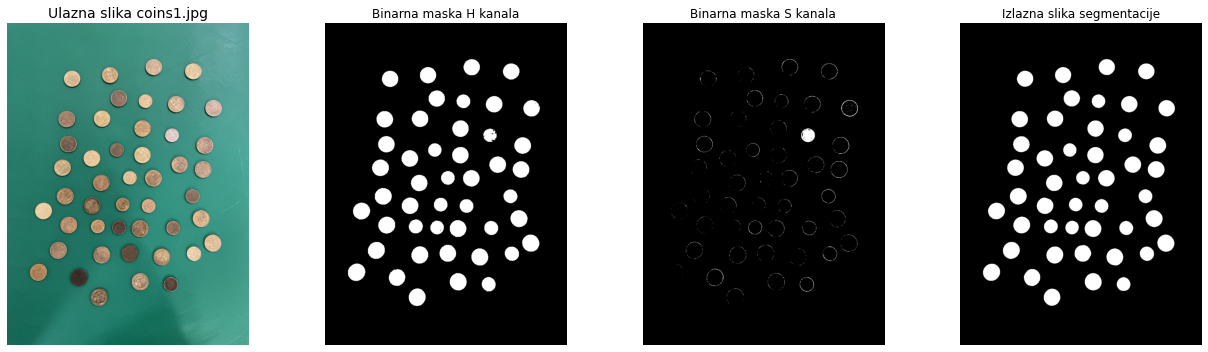

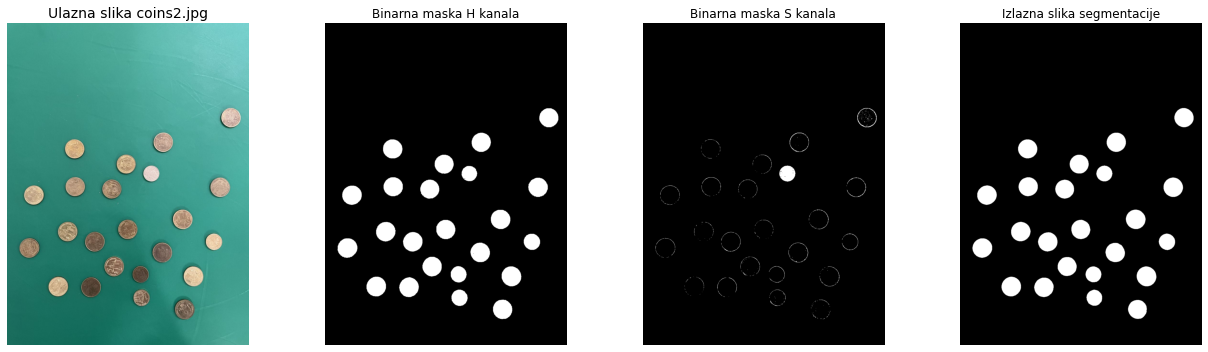

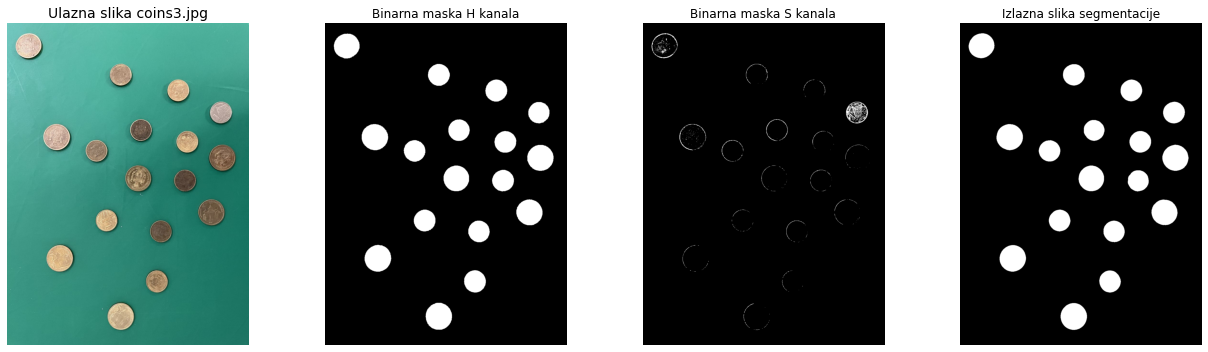

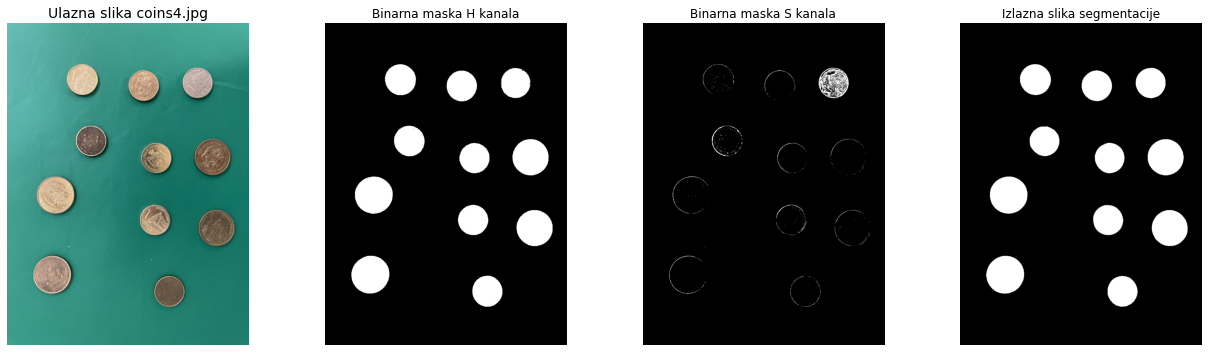

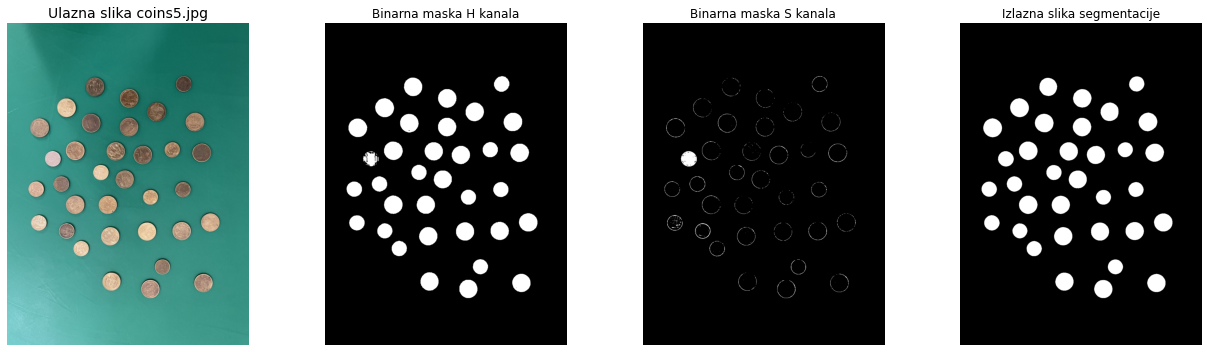

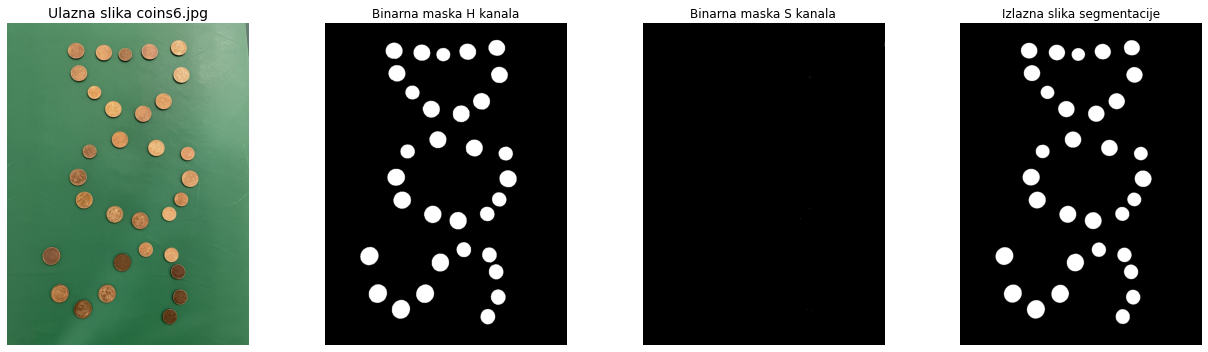

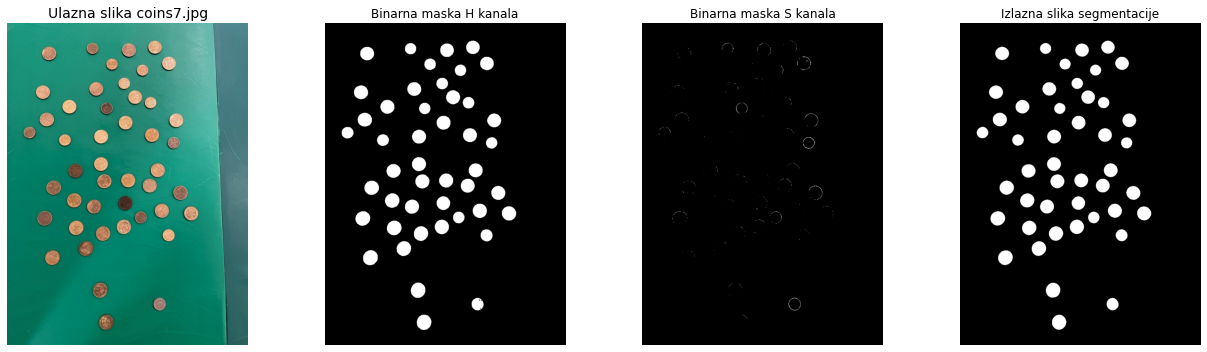

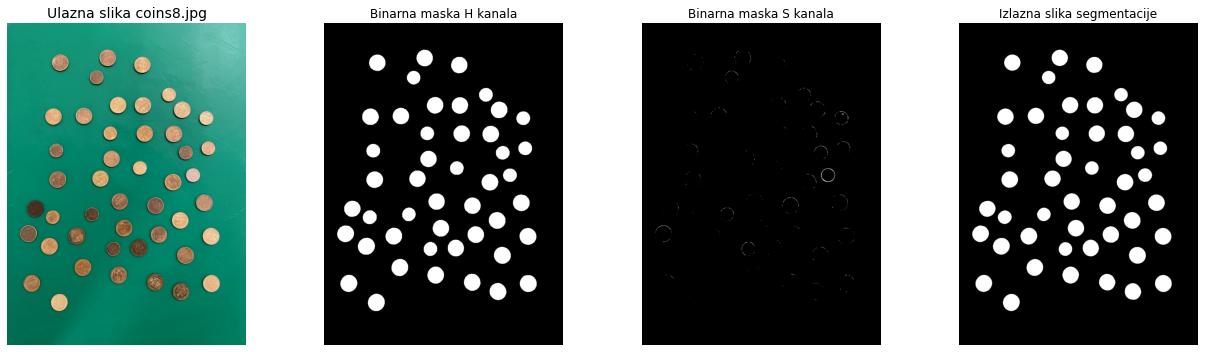

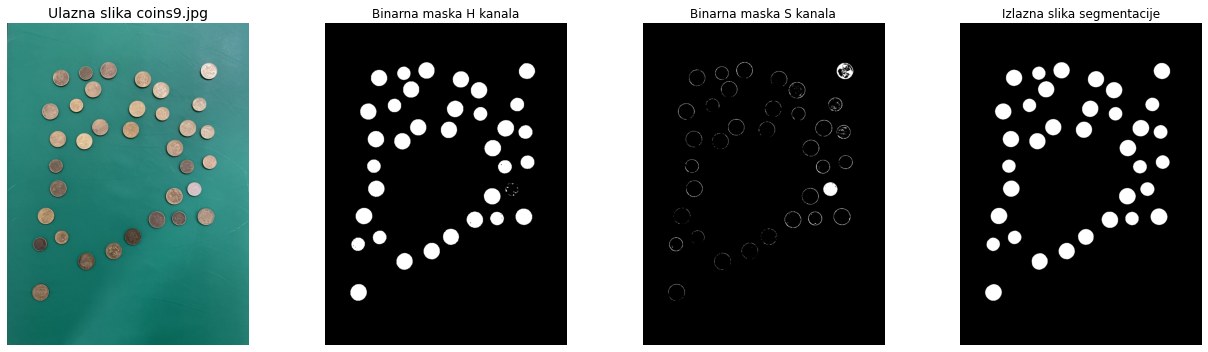

In [4]:
for i in range(1, 10):

    image = ski.io.imread(f"{data_dir}coins{i}.jpg")

    if image.dtype == 'uint8':
        image = ski.util.img_as_float(image)

    #maska
    img_bin = coin_mask(image)

    hsv = ski.color.rgb2hsv(image)
    H = hsv[:, :, 0]
    S = hsv[:, :, 1]

    thresh_H = ski.filters.threshold_otsu(H)
    mask_H = ~(H > thresh_H)

    mask_S = S < 0.14

    #prikaz slika
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(image)
    axes[0].set_title(f"Ulazna slika coins{i}.jpg", fontsize = 14)
    axes[0].axis("off")

    axes[1].imshow(mask_H, cmap="gray")
    axes[1].set_title("Binarna maska H kanala")
    axes[1].axis("off")

    axes[2].imshow(mask_S, cmap="gray")
    axes[2].set_title("Binarna maska S kanala")
    axes[2].axis("off")

    axes[3].imshow(img_bin, cmap="gray")
    axes[3].set_title("Izlazna slika segmentacije")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()
   

    

## DRUGA TACKA

Kao ulaz u funkciju bw_label koristim binarnu sliku dobijenu u prethodnom delu zadatka izvrsavanjem funkcije coin_mask, gde vrednost 1 predstavlja novcice, a 0 pozadinu.

Nakon toga pronalazim sve susedne piksele koji pripadaju istom novčiću. Pri tome koristim 8-povezanu okolinu, što znaci da posmatram i dijagonalne susede, kako bih bio siguran da ce ceo novcic biti obuhvacen jednom labelom. Svaki pronadjeni sused koji pripada objektu dobija istu oznaku, sve dok ne obidjem ceo region.

Na kraju ove funkcije dobijam sliku u kojoj svaki novcic ima svoju jedinstvenu oznaku, sto mi omogucava da lako odredim ukupan broj novcica i da te informacije kasnije iskoristim za njihovu detekciju i klasifikaciju.

In [5]:
def bw_label(img_bin):

    h, w = img_bin.shape
    bw_img = np.zeros_like(img_bin, dtype=np.int32)

    label = 0

    # 8-povezana okolina
    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 ( 0, -1),          ( 0, 1),
                 ( 1, -1), ( 1, 0), ( 1, 1)]

    for i in range(h):
        for j in range(w):

            # novi region
            if img_bin[i, j] == 1 and bw_img[i, j] == 0:
                label += 1
                stack = [(i, j)]
                bw_img[i, j] = label

                # pretraga regiona
                while stack:
                    x, y = stack.pop()

                    for dx, dy in neighbors:
                        nx = x + dx
                        ny = y + dy

                        # provera granica
                        if 0 <= nx < h and 0 <= ny < w:
                            if img_bin[nx, ny] == 1 and bw_img[nx, ny] == 0:
                                bw_img[nx, ny] = label
                                stack.append((nx, ny))

    return bw_img


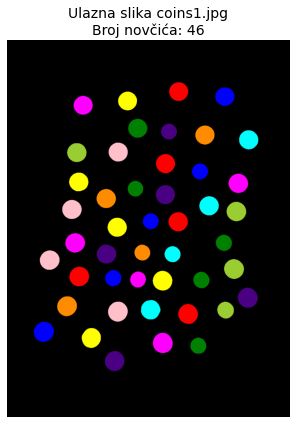

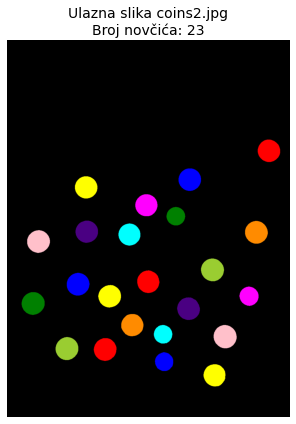

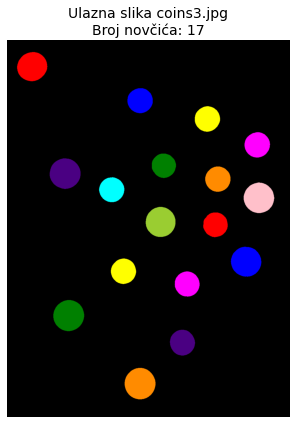

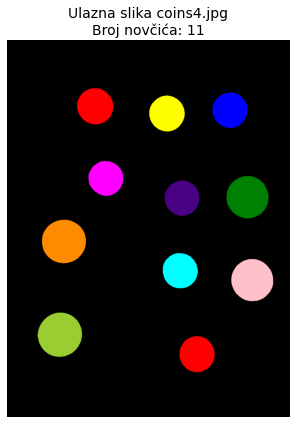

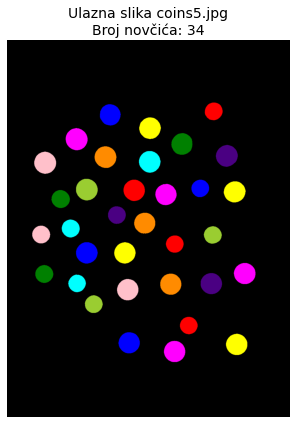

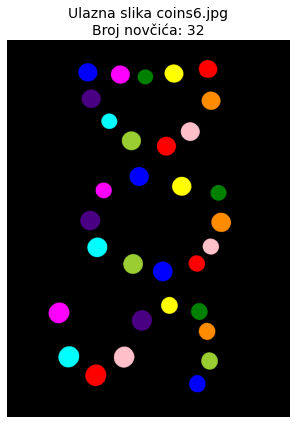

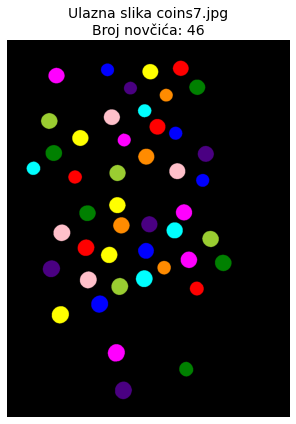

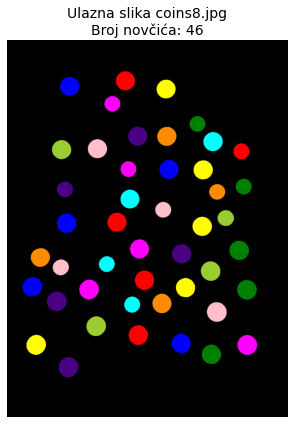

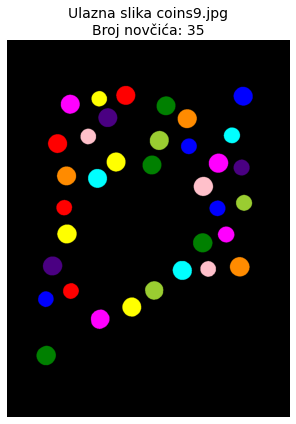

In [6]:
for i in range(1, 10):
    
    #Plotovanje slika na kojoj su oznaceni razliciti regioni i ispisani ukupni brojevi novcica na svakoj od slika

    image = ski.io.imread(data_dir + f'coins{i}.jpg')
    image = ski.util.img_as_float(image)

    img_bin = coin_mask(image)
    bw_img = bw_label(img_bin)

    #Koriscena ugradjena funkcija label2rgb 
    rgb = label2rgb(bw_img, bg_label=0, bg_color=(0, 0, 0))

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb)
    plt.axis('off')

    plt.title(f"Ulazna slika coins{i}.jpg\nBroj novčića: {bw_img.max()}",
              fontsize=14)

    plt.tight_layout()
    plt.show()
    



## TRECA TACKA

Ova funkcija sluzi da detektujem novcice na slici i da ih klasifikujem na osnovu njihove velicine. Kao prvi korak koristim prethodno implementiranu funkciju coin_mask kako bih dobio binarnu sliku na kojoj su jasno izdvojeni svi novcici. Nakon toga primenjujem funkciju bw_label, cime svakom novcicu dodeljujem jedinstvenu oznaku i na taj nacin dobijam informaciju o ukupnom broju novcica na slici.

Zatim nad binarnom slikom primenjujem ugradjenu funkciju za Canny algoritam(nije zadato u zadatku na koji nacin konkretno treba obaviti detekciju ivica pa mi najlakse bilo da koristim ugradjenu funkciju) kako bih izdvojio ivice novcica. Dobijene ivice koristim kao ulaz za Houghovu transformaciju za detekciju krugova. U ovoj fazi definisem opseg mogucih radijusa i na osnovu toga pronalazim centre i radijuse svih detektovanih krugova koji odgovaraju novcicima. 

Nakon sto dobijem radijuse svih novcica, sortiram ih i odredjujem granicnu vrednost kao sredinu izmedju najmanjeg i najveceg radijusa. Kako slike mogu biti razlicitih rezolucija, nije bilo moguce podesiti fiksan prag koji ce mi za svaku sliku jednako dobro razdvojiti novcice po velicini, tako da sam na osnovu slike formirao prag(olaksavajuca okolnost je sto su novcici na slikama ili od 1 din ili od 5 din) koji ce mi odrediti kojoj klasi pripada i broj novcica u jednoj i drugoj klasi. 

Na kraju funkcija vraca koordinate centara, radijuse, prag klasifikacije i ukupan broj novcica u obe klase, sto kasnije koristim za prikaz rezultata i analizu uspesnosti detekcije i klasifikacije.

In [7]:
def coin_classification(image):

    img_bin = coin_mask(image)
    bw_img = bw_label(img_bin)

    sigma = 4
    high_thr = 0.2
    low_thr = 0.15

    
    # izdvajam ivice novcica pomocu Canny algoritma
    image_canny = ski.feature.canny(image=img_bin, sigma=sigma, low_threshold=low_thr, high_threshold=high_thr)

    
    # definisem opseg mogucih radijusa novcica ovaj opseg je odredjen eksperimentalno na osnovu dimenzija novcica
    hough_radii = np.arange(20, 150)
    
    # primenjujem Hough transformaciju za detekciju krugova
    hough_res = ski.transform.hough_circle(image_canny, hough_radii)

    accums, cx, cy, radii = ski.transform.hough_circle_peaks(hough_res, hough_radii, min_xdistance=10, min_ydistance=10, total_num_peaks=bw_img.max())

    
    # sortiram radijuse kako bih odredio granicu klasifikacije
    radii_sorted = np.sort(radii)
    
    # prag klasifikacije odredjujem kao srednju vrednost izmedju najmanjeg i najveceg radijusa
    threshold = (radii_sorted[0] + radii_sorted[-1]) / 2
    
    
    # brojaci za novcice od 1 din i 5 din
    count_1din = 0
    count_5din = 0

    # klasifikujem novcice na osnovu radijusa
    for r in radii:
        if r < threshold:
            count_1din += 1
        else:
            count_5din += 1
            
    # vracam:
    # cx, cy - koordinate centara
    # radii - radijuse novcica
    # threshold - prag klasifikacije
    # count_1din, count_5din - broj novcica po klasama


    return cx, cy, radii, threshold, count_1din, count_5din


Ukupno na slici coins1.jpg:
1 din: 12, 5 din: 34


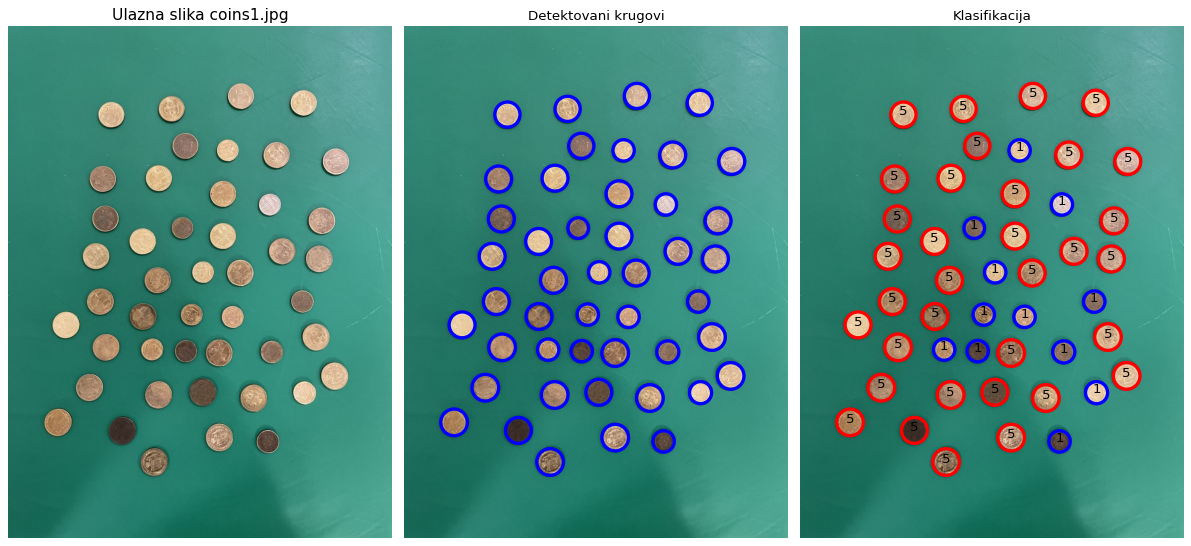

Ukupno na slici coins2.jpg:
1 din: 4, 5 din: 19


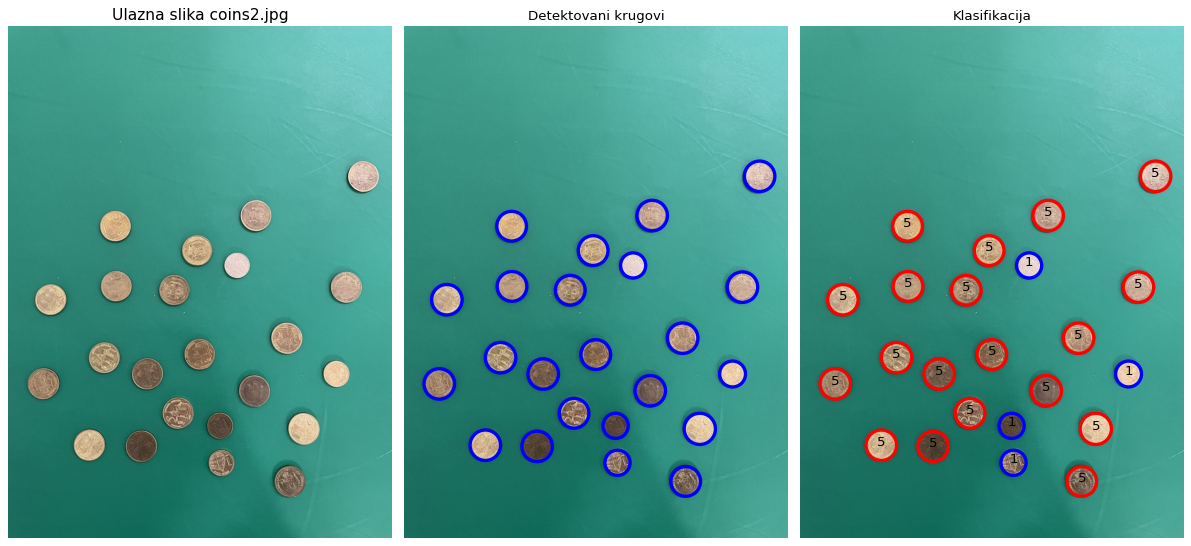

Ukupno na slici coins3.jpg:
1 din: 10, 5 din: 7


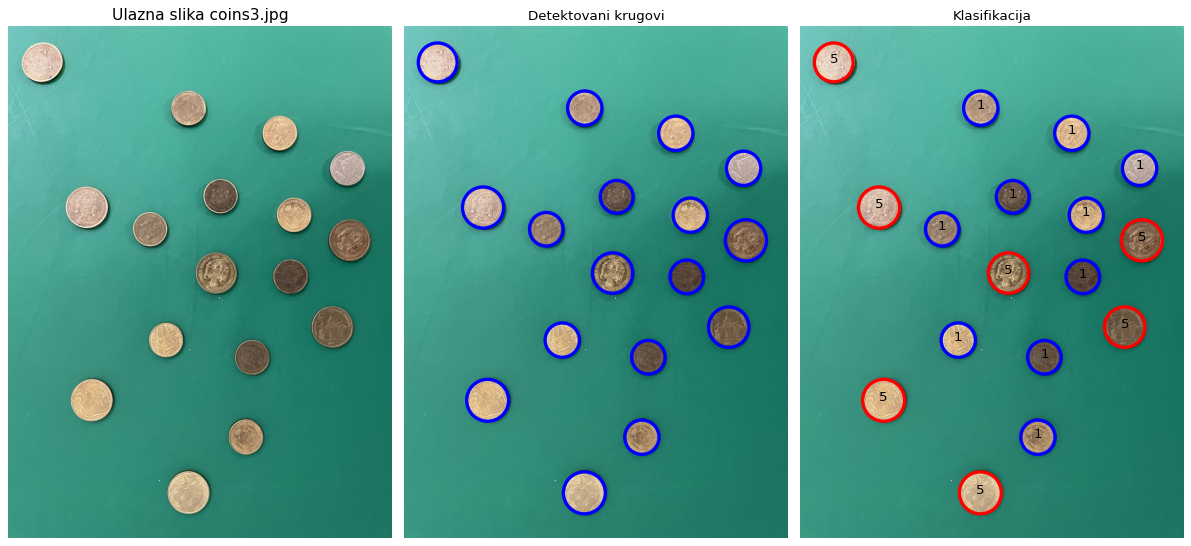

Ukupno na slici coins4.jpg:
1 din: 7, 5 din: 4


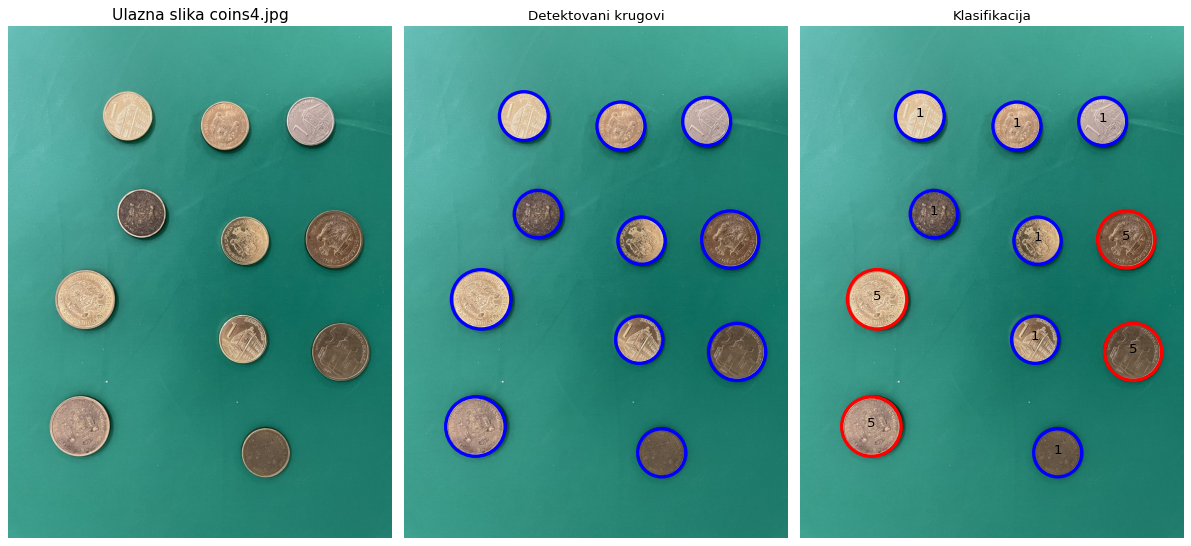

Ukupno na slici coins5.jpg:
1 din: 12, 5 din: 22


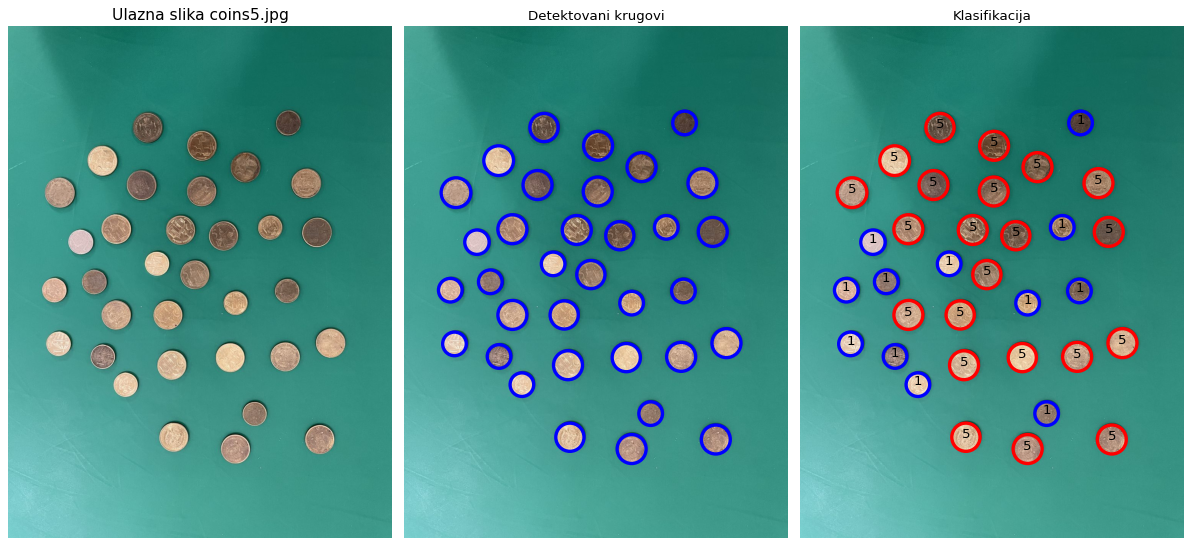

Ukupno na slici coins6.jpg:
1 din: 11, 5 din: 21


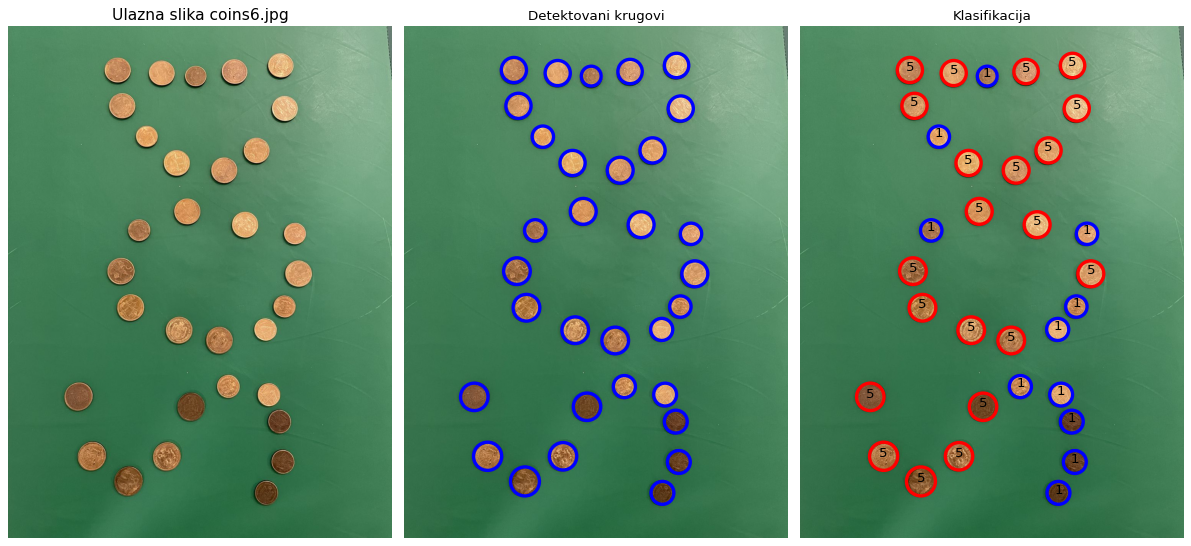

Ukupno na slici coins7.jpg:
1 din: 12, 5 din: 34


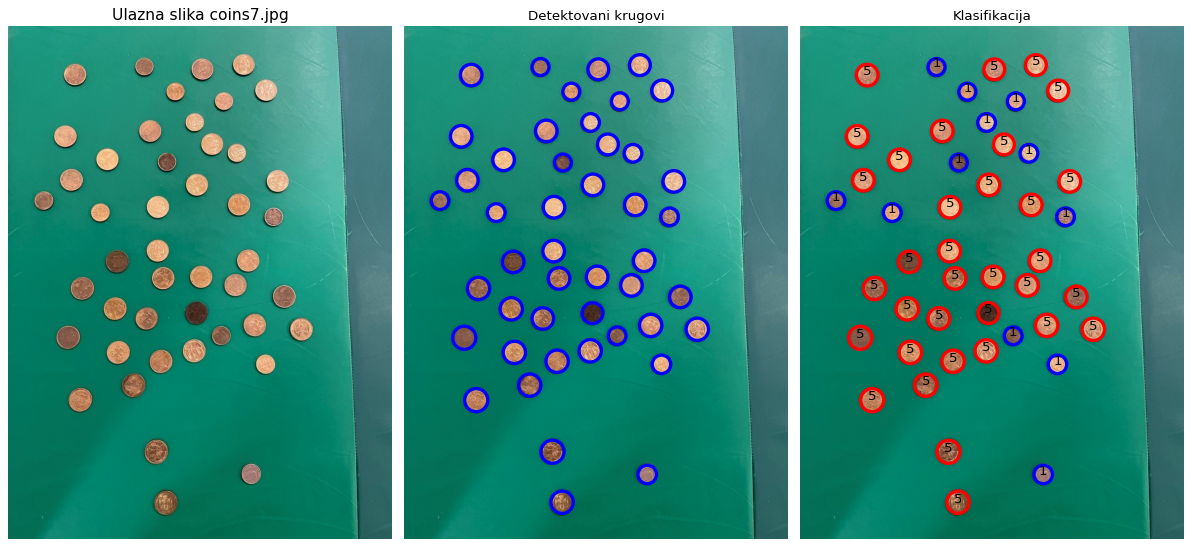

Ukupno na slici coins8.jpg:
1 din: 12, 5 din: 34


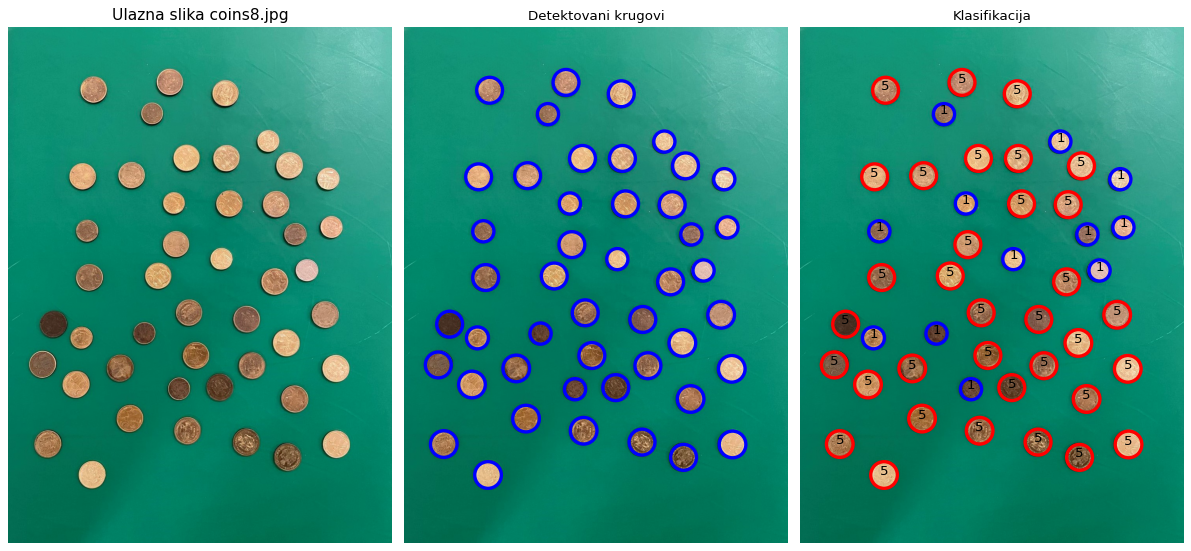

Ukupno na slici coins9.jpg:
1 din: 12, 5 din: 23


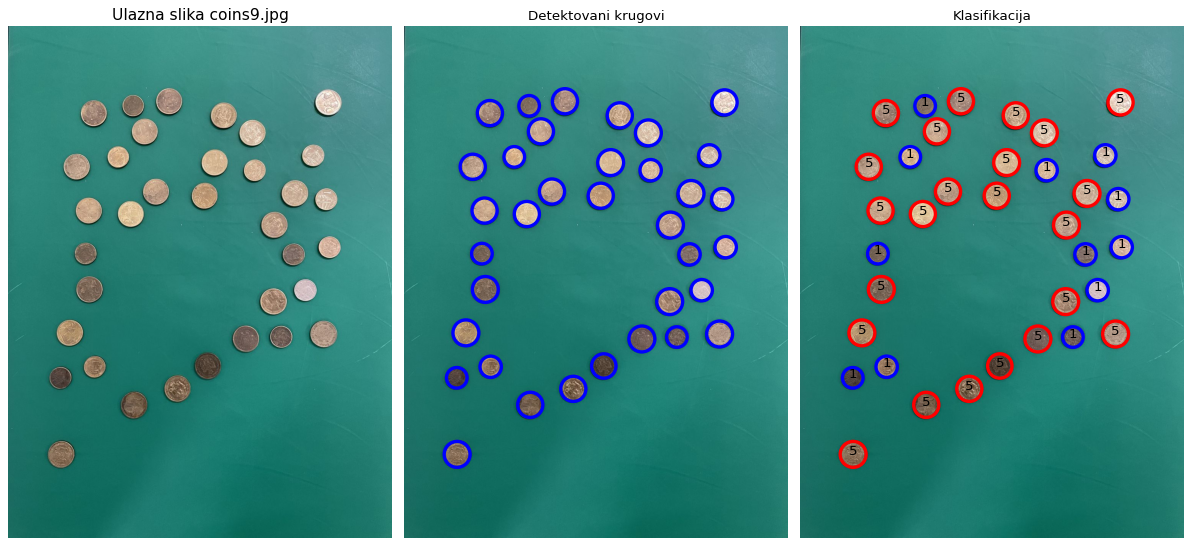

In [8]:
for i in range(1, 10):

    image = ski.io.imread(data_dir + f'coins{i}.jpg')
    image = ski.util.img_as_float(image)

    cx, cy, radii, threshold, count_1din, count_5din, = coin_classification(image)
    
    print(f"Ukupno na slici coins{i}.jpg:")
    print(f"1 din: {count_1din}, 5 din: {count_5din}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 8), dpi=80)

    # Original
    axes[0].imshow(image)
    axes[0].set_title(f'Ulazna slika coins{i}.jpg', fontsize = 14)
    axes[0].axis('off')

    # Svi krugovi plavi
    axes[1].imshow(image)
    axes[1].set_title('Detektovani krugovi')
    axes[1].axis('off')

    for center_x, center_y, radius in zip(cx, cy, radii):
        circle = plt.Circle((center_x, center_y), radius, color='b', fill=False, linewidth=3)
        axes[1].add_artist(circle)

    # Klasifikacija
    axes[2].imshow(image)
    axes[2].set_title('Klasifikacija')
    axes[2].axis('off')

    for center_x, center_y, radius in zip(cx, cy, radii):

        if radius < threshold:
            color = 'b'      # 1 din
            label = "1"
        else:
            color = 'r'      # 5 din
            label = "5"

        circle = plt.Circle((center_x, center_y), radius, color=color, fill=False, linewidth=3)

        axes[2].add_artist(circle)

        axes[2].text(center_x, center_y, label, color='black', fontsize=12, ha='center')

    plt.tight_layout()
    plt.savefig(f"coins{i}_classified.png", dpi=300, bbox_inches='tight')
    plt.show()


### 2. ZADATAK


Kao prvi korak sam proverio tip ulazne slike i, ukoliko je bila u uint8 formatu, prebacio sam je u float opseg od 0 do 1.

Nakon toga sam izvrsio Gausovo filtriranje kako bih uklonio sum i smanjio uticaj sitnih varijacija u slici. Velicinu Gausovog prozora sam odredio kao prvi neparni ceo broj veci ili jednak od 6 sigma, cime je ispostovan uslov iz zadatka. Filtriranjem sam dobio ugladjenu verziju slike pogodnu za racunanje gradijenata.

U sledecem koraku sam pomocu Sobel operatora izracunao horizontalni i vertikalni gradijent slike. Na osnovu njih sam zatim odredio magnitudu gradijenta, koja predstavlja jacinu ivice, kao i ugao gradijenta, koji predstavlja pravac ivice. Ugao sam zatim kvantizovao na cetiri osnovna pravca: 0, 45, 90 i 135 stepeni, kako bih mogao pravilno da izvrsim potiskivanje vrednosti koje ne predstavljaju lokalne maksimume.

Potiskivanje ne-maksimalnih vrednosti sam realizovao tako sto sam za svaki piksel poredio njegovu vrednost magnitude sa susedima u odgovarajucem pravcu gradijenta. Ukoliko piksel nije bio lokalni maksimum, njegova vrednost je potisnuta, cime sam dobio tanje i preciznije ivice.

Nakon toga sam izdvojio jake ivice kao one cija je vrednost veca od viseg praga, i slabe ivice kao one cija je vrednost izmedju nizeg i viseg praga. U poslednjem koraku sam primenio histerezis, gde sam zadrzao samo one slabe ivice koje su povezane sa nekim jakim ivicama, cime sam uklonio izolovane i lazne ivice.

Kao rezultat funkcije dobijam konacnu mapu ivica, kao i medjurezultate poput filtrirane slike, magnitude gradijenta, kvantizovanog ugla i slike nakon potiskivanja ne-maksimalnih vrednosti.

In [9]:
def canny_edge_detection(I, sigma, low_thr, high_thr):

    # ako je uint8 → float
    if I.dtype == np.uint8:
        I = I.astype(np.float64) / 255.0


    # 1. Gausovo filtriranje


    size = int(np.ceil(6 * sigma))

    if size % 2 == 0:
        size += 1

    truncate = (size - 1) / (2 * sigma)

    smoothed = ndi.gaussian_filter(I, sigma=sigma, truncate=truncate)


    # 2. Gradijenti (Sobel)


    Gx = ndi.sobel(smoothed, axis=1)
    Gy = ndi.sobel(smoothed, axis=0)


    # 3. Magnituda i ugao

    mag = np.sqrt(Gx**2 + Gy**2)

    ugao = np.arctan2(Gy, Gx) * 180 / np.pi

    ugao[ugao < 0] += 180



    # 4. Kvantizacija ugla (4 pravca)


    quantized = np.zeros_like(ugao)

    quantized[(ugao >= 0) & (ugao < 22.5)] = 0
    quantized[(ugao >= 157.5) & (ugao <= 180)] = 0

    quantized[(ugao >= 22.5) & (ugao < 67.5)] = 45

    quantized[(ugao >= 67.5) & (ugao < 112.5)] = 90

    quantized[(ugao >= 112.5) & (ugao < 157.5)] = 135


    # 5. Potiskivanje vrednosti gradijenta


    H, W = mag.shape
    nms = np.zeros_like(mag)

    for i in range(1, H-1):
        for j in range(1, W-1):

            direction = quantized[i, j]
            value = mag[i, j]

            if direction == 0:
                neighbors = [mag[i, j-1], mag[i, j+1]]

            elif direction == 45:
                neighbors = [mag[i-1, j+1], mag[i+1, j-1]]

            elif direction == 90:
                neighbors = [mag[i-1, j], mag[i+1, j]]

            elif direction == 135:
                neighbors = [mag[i-1, j-1], mag[i+1, j+1]]

            if value >= neighbors[0] and value >= neighbors[1]:
                nms[i, j] = value


    # 6. Pragovi


    strong = nms >= high_thr

    weak = (nms >= low_thr) & (nms < high_thr)


    # 7. Histerezis


    edges = strong.copy()

    stack = list(zip(*np.where(strong)))

    while stack:

        i, j = stack.pop()

        for di in [-1, 0, 1]:
            for dj in [-1, 0, 1]:

                ni = i + di
                nj = j + dj

                if 0 <= ni < H and 0 <= nj < W:

                    if weak[ni, nj] and not edges[ni, nj]:

                        edges[ni, nj] = True
                        stack.append((ni, nj))


    return edges.astype(np.uint8), smoothed, mag, quantized, nms


Kako dolazim do optimalnih vrednosti parametara za bolje rezultate?

Sigma:

Ako sigma ima malu vrednost, filtriranje je blago i slika zadrzava vise detalja, ali i vise suma moze da se detektuje kao ivica.

Ako sigma ima vecu vrednost, filtriranje je jace i sitni detalji i sum se uklanjaju, ali i neke prave ivice mogu da budu izgubljene ili slabije prikazane.

Pragovi:

Ako su pragovi niski, mnogo piksela se klasifikuje kao slabe ili jake ivice, pa mapa ivica postaje "gusca" i moze da ukljuci sum.

Ako su pragovi visoki, detektuju se samo najjace ivice, sto moze da izazove gubitak detalja ili nepotpune ivice.

U eksperimentima sam primecivao da kombinacija umerene vrednosti sigma i umerenih pragova daje balans izmedju uklanjanja suma i zadrzavanja glavnih ivica. 

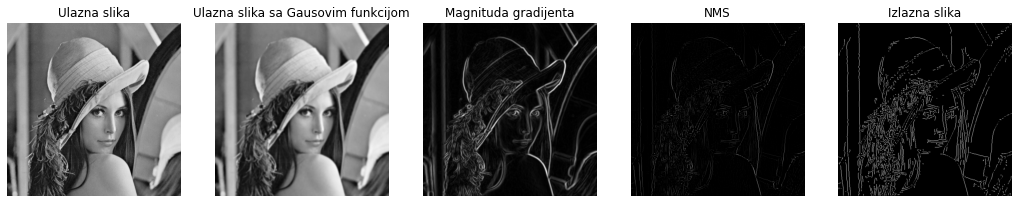

In [10]:
image = io.imread(data_dir + 'lena.tif', as_gray=True)

#Lena.tif sa jednim setom parametara

edges, smoothed, mag, quantized, nms = canny_edge_detection(image, sigma=1.5, low_thr=0.05, high_thr=0.15)

fig, axes = plt.subplots(1,5, figsize=(18,5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Ulazna slika")

axes[1].imshow(smoothed, cmap='gray')
axes[1].set_title("Ulazna slika sa Gausovim funkcijom")

axes[2].imshow(mag, cmap='gray')
axes[2].set_title("Magnituda gradijenta")

axes[3].imshow(nms, cmap='gray')
axes[3].set_title("NMS")

axes[4].imshow(edges, cmap='gray')
axes[4].set_title("Izlazna slika")

for ax in axes:
    ax.axis('off')

plt.show()

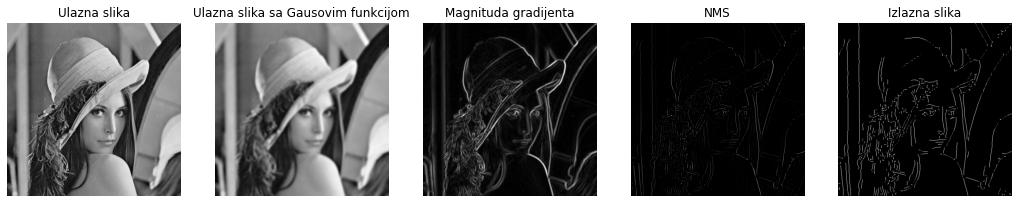

In [11]:
image = io.imread(data_dir + 'lena.tif', as_gray=True)

#Lena.tif sa drugim setom parametara

edges, smoothed, magnitude, quantized, nms = canny_edge_detection(image, sigma=2.5, low_thr=0.08, high_thr=0.18)

fig, axes = plt.subplots(1,5, figsize=(18,5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Ulazna slika")

axes[1].imshow(smoothed, cmap='gray')
axes[1].set_title("Ulazna slika sa Gausovim funkcijom")

axes[2].imshow(mag, cmap='gray')
axes[2].set_title("Magnituda gradijenta")

axes[3].imshow(nms, cmap='gray')
axes[3].set_title("NMS")

axes[4].imshow(edges, cmap='gray')
axes[4].set_title("Izlazna slika")

for ax in axes:
    ax.axis('off')

plt.show()

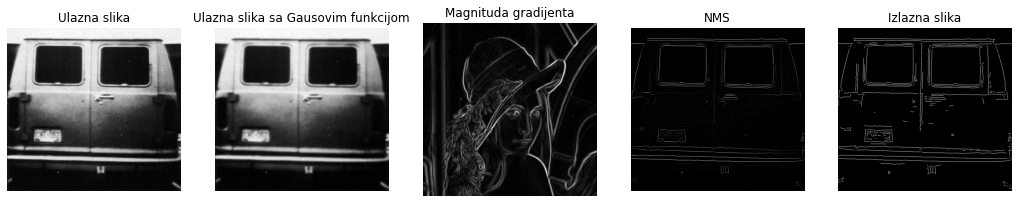

In [12]:
image = io.imread(data_dir + 'van.tif', as_gray=True)

edges, smoothed, magnitude, quantized, nms = canny_edge_detection(image, sigma=1.5, low_thr=0.1, high_thr=0.2)

fig, axes = plt.subplots(1,5, figsize=(18,5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Ulazna slika")

axes[1].imshow(smoothed, cmap='gray')
axes[1].set_title("Ulazna slika sa Gausovim funkcijom")

axes[2].imshow(mag, cmap='gray')
axes[2].set_title("Magnituda gradijenta")

axes[3].imshow(nms, cmap='gray')
axes[3].set_title("NMS")

axes[4].imshow(edges, cmap='gray')
axes[4].set_title("Izlazna slika")

for ax in axes:
    ax.axis('off')

plt.show()

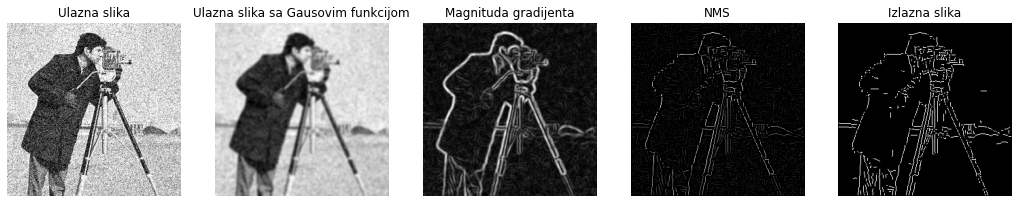

In [13]:
image = io.imread(data_dir + 'camerman.tif', as_gray=True)

edges, smoothed, magnitude, quantized, nms = canny_edge_detection(image, sigma=1.5, low_thr=0.2, high_thr=0.35)

fig, axes = plt.subplots(1,5, figsize=(18,5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Ulazna slika")

axes[1].imshow(smoothed, cmap='gray')
axes[1].set_title("Ulazna slika sa Gausovim funkcijom")

axes[2].imshow(magnitude, cmap='gray')
axes[2].set_title("Magnituda gradijenta")

axes[3].imshow(nms, cmap='gray')
axes[3].set_title("NMS")

axes[4].imshow(edges, cmap='gray')
axes[4].set_title("Izlazna slika")

for ax in axes:
    ax.axis('off')

plt.show()